In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBRegressor

import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
DATA_DIR = Path("../data/processed")

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

for dataset in [train_df, val_df, test_df]:
    dataset["occupied_date"] = pd.to_datetime(
        dataset["occupied_date"]
    )

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (9248, 20)
Validation: (1989, 20)
Testing: (1989, 20)


In [3]:
print("Training ends:", train_df["occupied_date"].max())
print("Validation starts:", val_df["occupied_date"].min())

print("Validation ends:", val_df["occupied_date"].max())
print("Testing starts:", test_df["occupied_date"].min())

Training ends: 2017-01-22 00:00:00
Validation starts: 2017-01-23 00:00:00
Validation ends: 2017-05-19 00:00:00
Testing starts: 2017-05-20 00:00:00


In [4]:
FEATURES = [
    "hotel",
    "room_category",
    "day_of_week",
    "day",
    "month",
    "year",
    "quarter",
    "day_of_year",
    "is_weekend",
    "season",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_std_7"
]

TARGET = "occupied_room_nights"

In [5]:
CATEGORICAL_FEATURES = [
    "hotel",
    "room_category",
    "season"
]

NUMERICAL_FEATURES = [
    col for col in FEATURES
    if col not in CATEGORICAL_FEATURES
]


In [6]:
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

In [7]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (9248, 18)
y_train: (9248,)
X_val: (1989, 18)
y_val: (1989,)


In [9]:
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    total_actual = np.abs(
        np.asarray(y_true)
    ).sum()

    wape = (
        np.abs(
            np.asarray(y_true) - np.asarray(y_pred)
        ).sum() / total_actual * 100
        if total_actual > 0
        else np.nan
    )

    return {
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "WAPE (%)": round(wape, 3)
    }

In [10]:
naive_predictions = val_df["lag_1"].values

naive_results = evaluate_model(
    y_val,
    naive_predictions
)

print("Naive Forecast Results:")
print(naive_results)

Naive Forecast Results:
{'MAE': 1.866, 'RMSE': np.float64(3.899), 'WAPE (%)': np.float64(10.678)}


In [11]:
seasonal_predictions = val_df["lag_7"].values

seasonal_results = evaluate_model(
    y_val,
    seasonal_predictions
)

print("Seasonal Naive Results:")
print(seasonal_results)

Seasonal Naive Results:
{'MAE': 3.607, 'RMSE': np.float64(7.155), 'WAPE (%)': np.float64(20.642)}


In [12]:
baseline_comparison = pd.DataFrame([
    {
        "Model": "Naive",
        **naive_results
    },
    {
        "Model": "Seasonal Naive",
        **seasonal_results
    }
])

display(baseline_comparison)

,Model,MAE,RMSE,WAPE (%)
0,Naive,1.866,3.899,10.678
1,Seasonal Naive,3.607,7.155,20.642


In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            CATEGORICAL_FEATURES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_FEATURES
        )
    ]
)

In [22]:
random_forest = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

In [23]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest)
    ]
)

In [24]:
rf_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [25]:
rf_predictions = rf_pipeline.predict(
    X_val
)

rf_predictions = np.maximum(
    rf_predictions,
    0
)

rf_results = evaluate_model(
    y_val,
    rf_predictions
)

print("Random Forest Results:")
print(rf_results)

Random Forest Results:
{'MAE': 2.011, 'RMSE': np.float64(3.882), 'WAPE (%)': np.float64(11.511)}


In [26]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [27]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", xgb_model)
    ]
)

In [28]:
xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost training completed!")

XGBoost training completed!


In [29]:
xgb_predictions = xgb_pipeline.predict(
    X_val
)

xgb_predictions = np.maximum(
    xgb_predictions,
    0
)

xgb_results = evaluate_model(
    y_val,
    xgb_predictions
)

print("XGBoost Results:")
print(xgb_results)

XGBoost Results:
{'MAE': 1.994, 'RMSE': np.float64(3.919), 'WAPE (%)': np.float64(11.409)}


In [30]:
results = pd.DataFrame([
    {
        "Model": "Naive",
        **naive_results
    },
    {
        "Model": "Seasonal Naive",
        **seasonal_results
    },
    {
        "Model": "Random Forest",
        **rf_results
    },
    {
        "Model": "XGBoost",
        **xgb_results
    }
])

results = results.sort_values(
    by="MAE"
).reset_index(drop=True)

display(results)

,Model,MAE,RMSE,WAPE (%)
0,Naive,1.866,3.899,10.678
1,XGBoost,1.994,3.919,11.409
2,Random Forest,2.011,3.882,11.511
3,Seasonal Naive,3.607,7.155,20.642


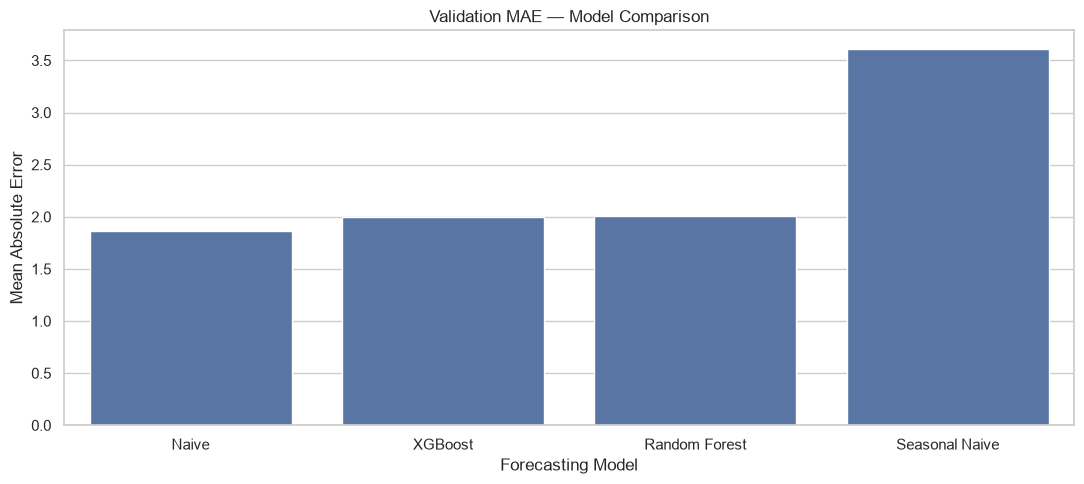

In [31]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=results,
    x="Model",
    y="MAE"
)

plt.title("Validation MAE — Model Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error")

plt.tight_layout()
plt.show()

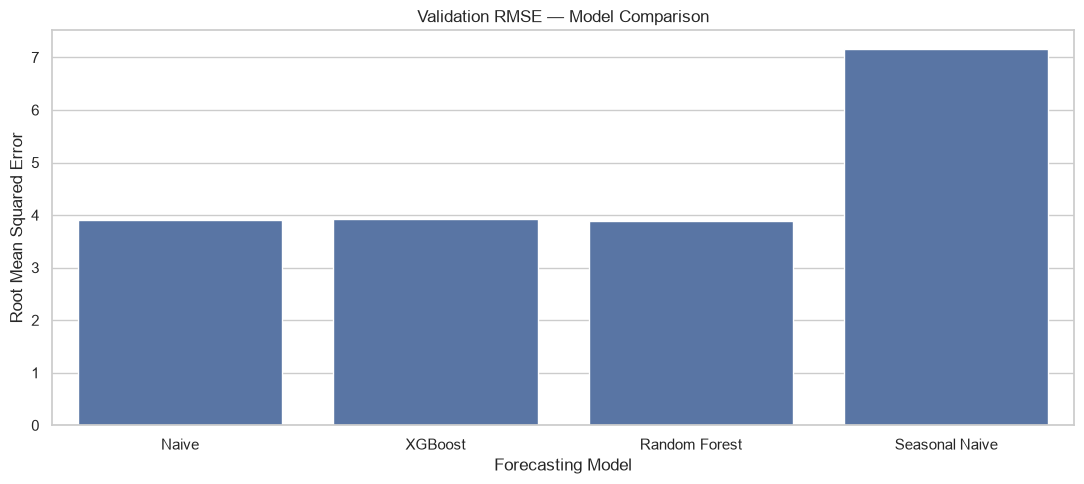

In [32]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("Validation RMSE — Model Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("Root Mean Squared Error")

plt.tight_layout()
plt.show()

In [33]:
rf_preprocessor = (
    rf_pipeline.named_steps["preprocessor"]
)

rf_estimator = (
    rf_pipeline.named_steps["model"]
)

feature_names = (
    rf_preprocessor.get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
23,numerical__lag_1,0.970541
27,numerical__rolling_mean_7,0.003964
28,numerical__rolling_mean_14,0.003277
30,numerical__rolling_std_7,0.003065
26,numerical__lag_28,0.002864
16,numerical__day_of_week,0.002794
29,numerical__rolling_mean_28,0.002764
24,numerical__lag_7,0.002536
21,numerical__day_of_year,0.002416
25,numerical__lag_14,0.002328


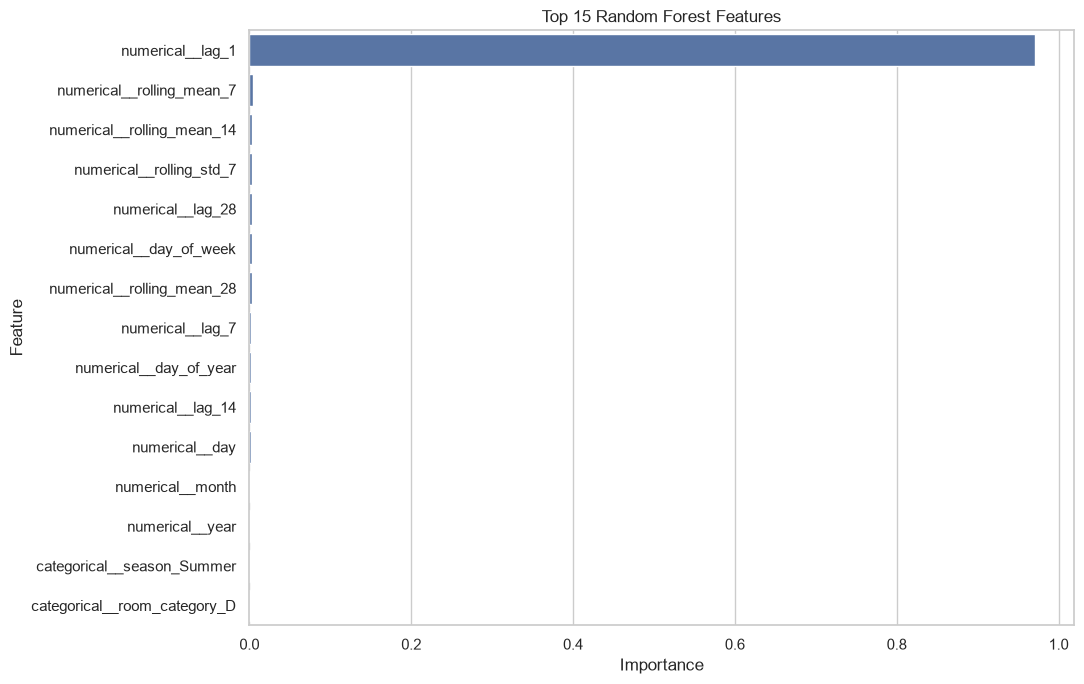

In [34]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Features")

plt.tight_layout()
plt.show()

In [35]:
validation_analysis = val_df[
    [
        "occupied_date",
        "hotel",
        "room_category",
        TARGET
    ]
].copy()

validation_analysis["rf_prediction"] = (
    rf_predictions
)

validation_analysis["xgb_prediction"] = (
    xgb_predictions
)

validation_analysis["rf_error"] = (
    validation_analysis[TARGET]
    - validation_analysis["rf_prediction"]
)

validation_analysis["xgb_error"] = (
    validation_analysis[TARGET]
    - validation_analysis["xgb_prediction"]
)

validation_analysis["rf_absolute_error"] = (
    validation_analysis["rf_error"].abs()
)

validation_analysis["xgb_absolute_error"] = (
    validation_analysis["xgb_error"].abs()
)

In [36]:
hotel_error = (
    validation_analysis.groupby("hotel")
    .agg(
        RF_MAE=("rf_absolute_error", "mean"),
        XGB_MAE=("xgb_absolute_error", "mean"),
        Actual_Demand=(TARGET, "sum")
    )
    .reset_index()
)

display(hotel_error)

,hotel,RF_MAE,XGB_MAE,Actual_Demand
0,City Hotel,2.260072,2.308014,19251.0
1,Resort Hotel,1.790170,1.713999,15503.0


In [37]:
room_error = (
    validation_analysis.groupby("room_category")
    .agg(
        RF_MAE=("rf_absolute_error", "mean"),
        XGB_MAE=("xgb_absolute_error", "mean"),
        Actual_Demand=(TARGET, "sum")
    )
    .reset_index()
)

display(room_error)

,room_category,RF_MAE,XGB_MAE,Actual_Demand
0,A,6.914268,6.940551,17635.0
1,B,0.441098,0.422961,216.0
2,C,0.890197,0.845125,1079.0
3,D,3.740646,3.812267,9438.0
4,E,1.722198,1.629897,3518.0
5,F,1.291019,1.264614,1385.0
6,G,1.035424,1.001080,875.0
7,H,0.669466,0.635067,181.0
8,I,0.714035,0.722208,216.0
9,K,0.738907,0.699837,211.0


In [38]:
ARTIFACT_DIR = Path("../backend/artifacts")

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [39]:
joblib.dump(
    rf_pipeline,
    ARTIFACT_DIR / "random_forest.joblib"
)

joblib.dump(
    xgb_pipeline,
    ARTIFACT_DIR / "xgboost.joblib"
)

print("Models saved successfully!")

Models saved successfully!


In [40]:
REPORT_DIR = Path("../reports")

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results.to_csv(
    REPORT_DIR / "validation_model_comparison.csv",
    index=False
)

In [41]:
validation_analysis.to_csv(
    REPORT_DIR / "validation_predictions.csv",
    index=False
)